# Analyse de Fourier

In [1]:
import numpy as np
import skimage as ski
import skimage.io as io
import matplotlib.pyplot as plt
import scipy.ndimage as ndi

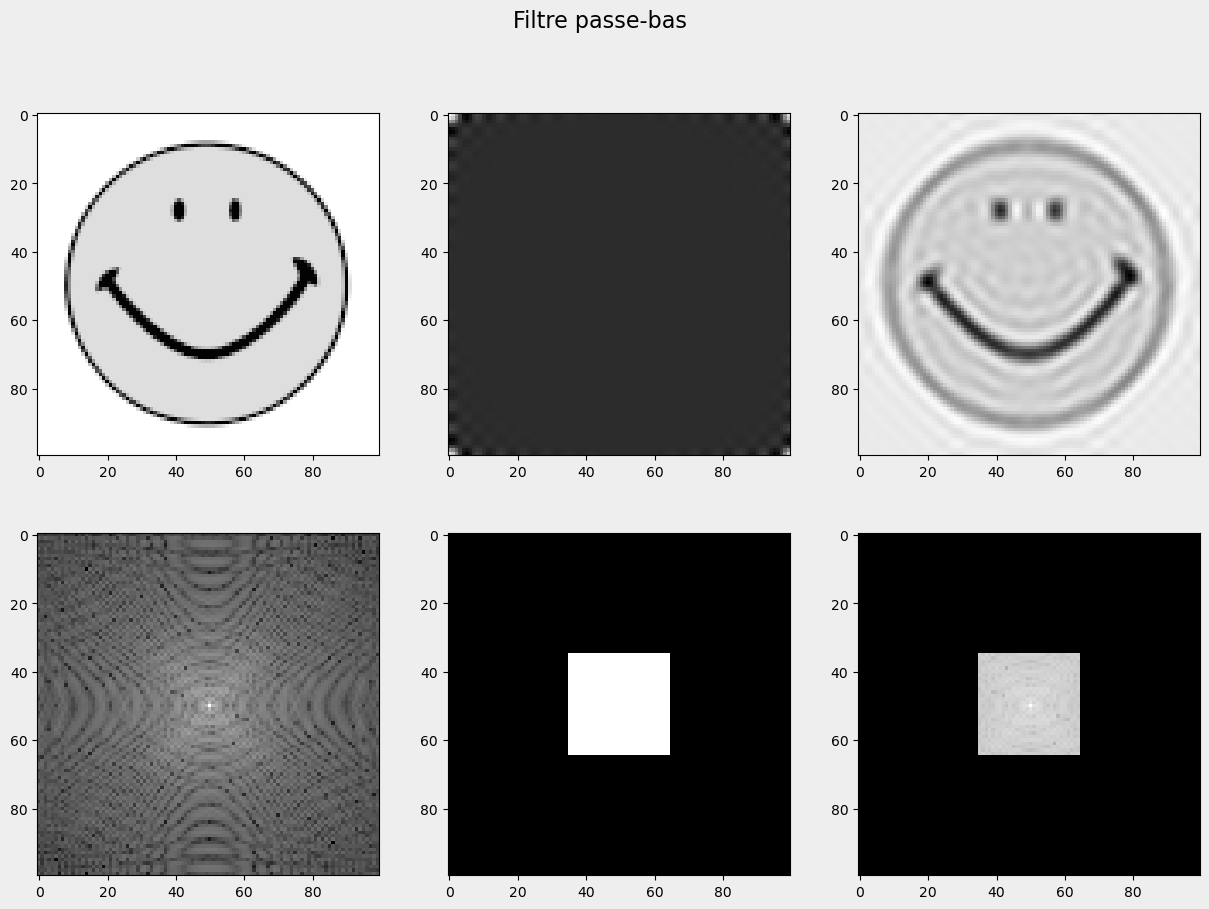

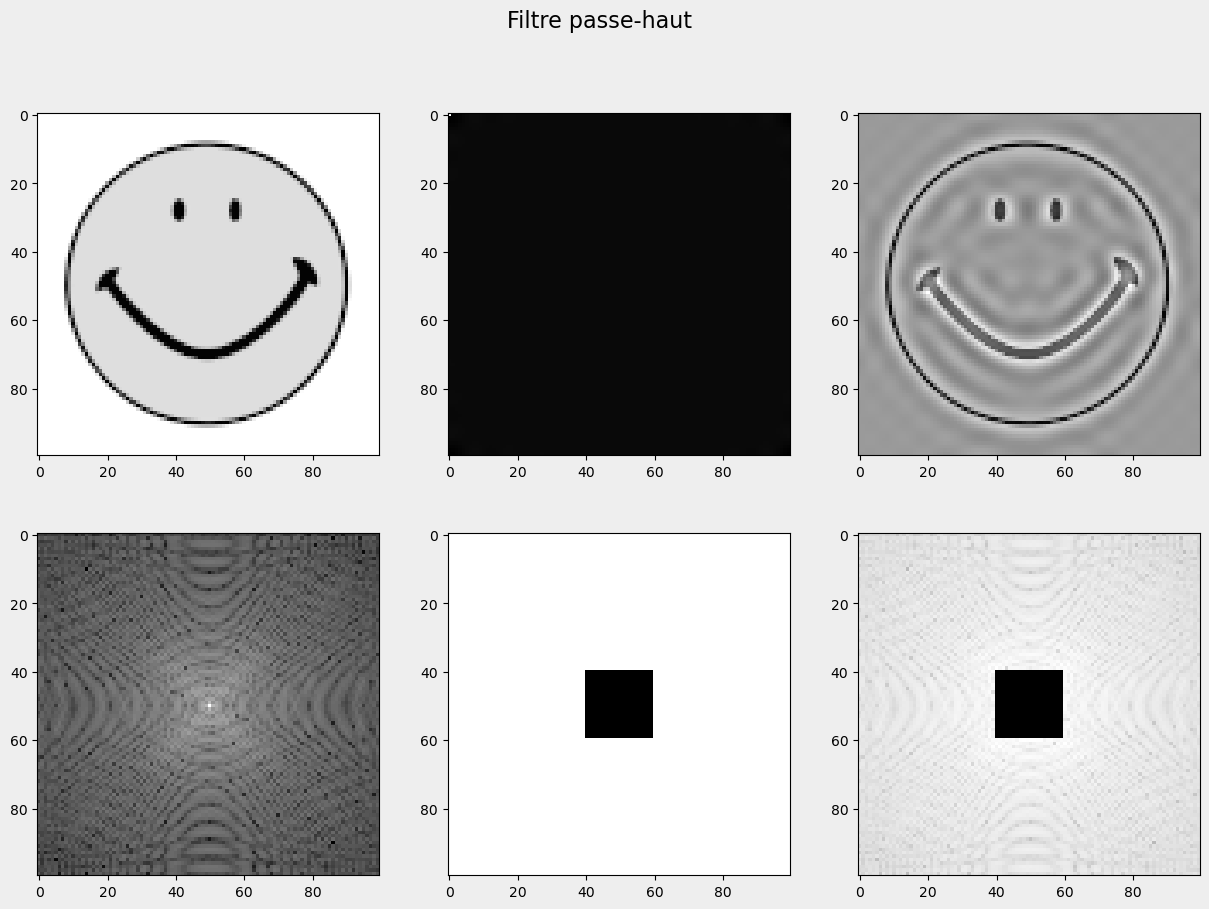

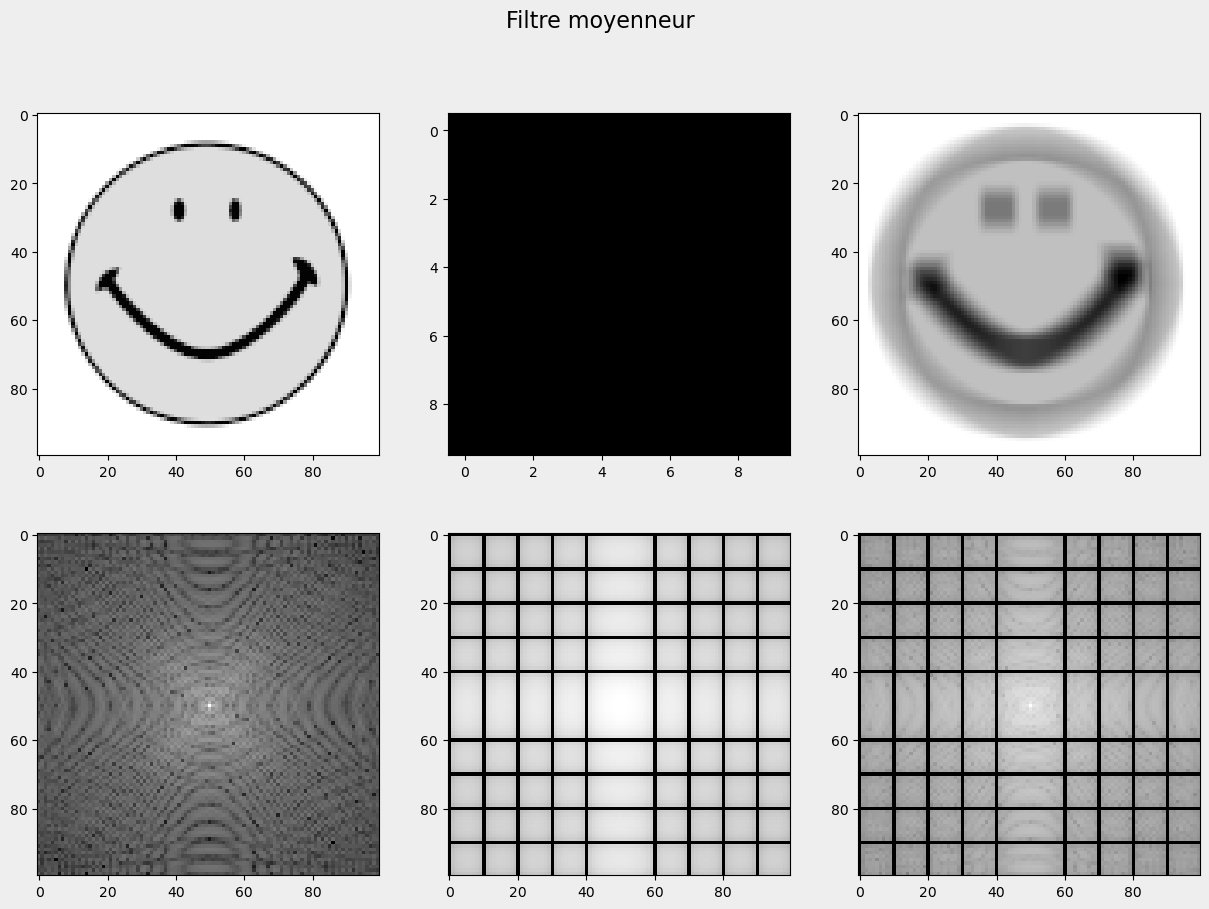

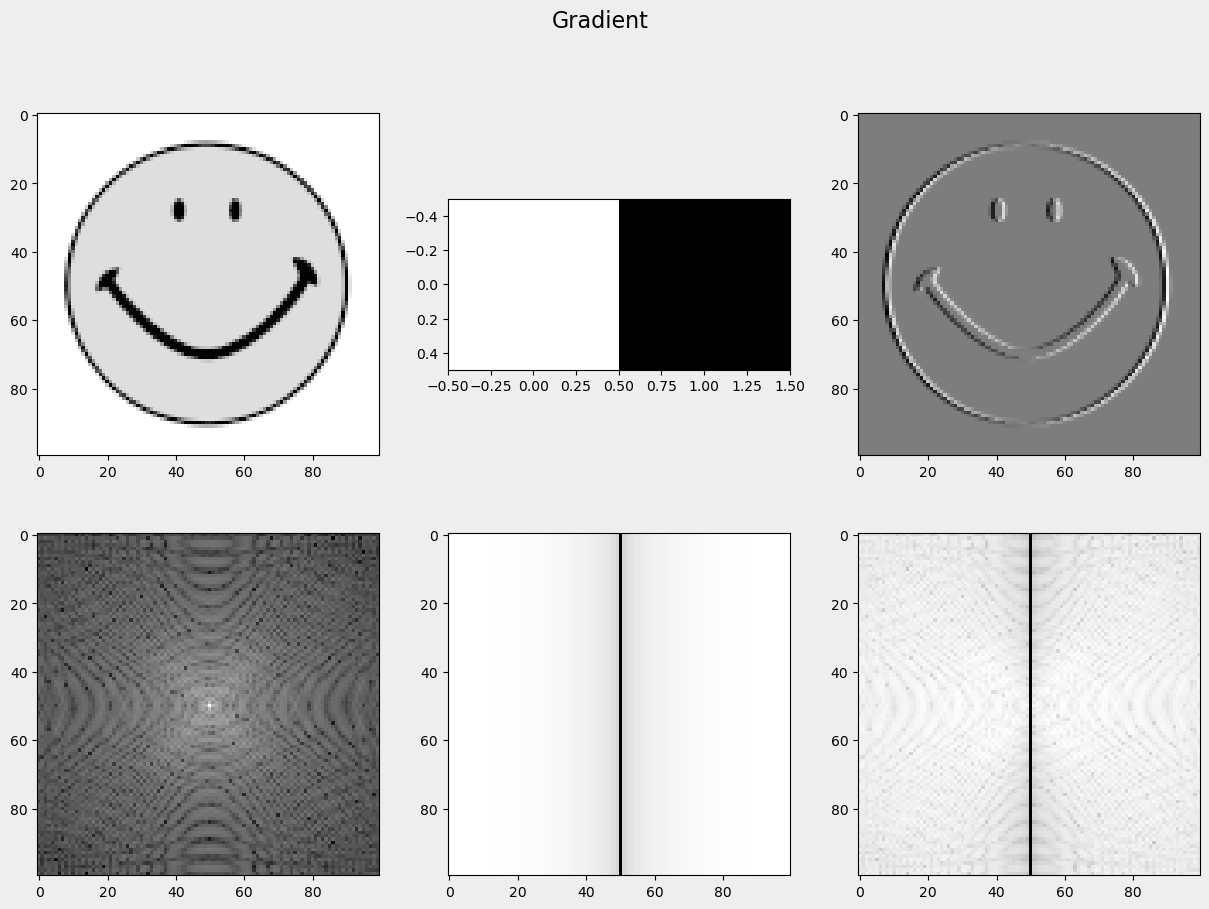

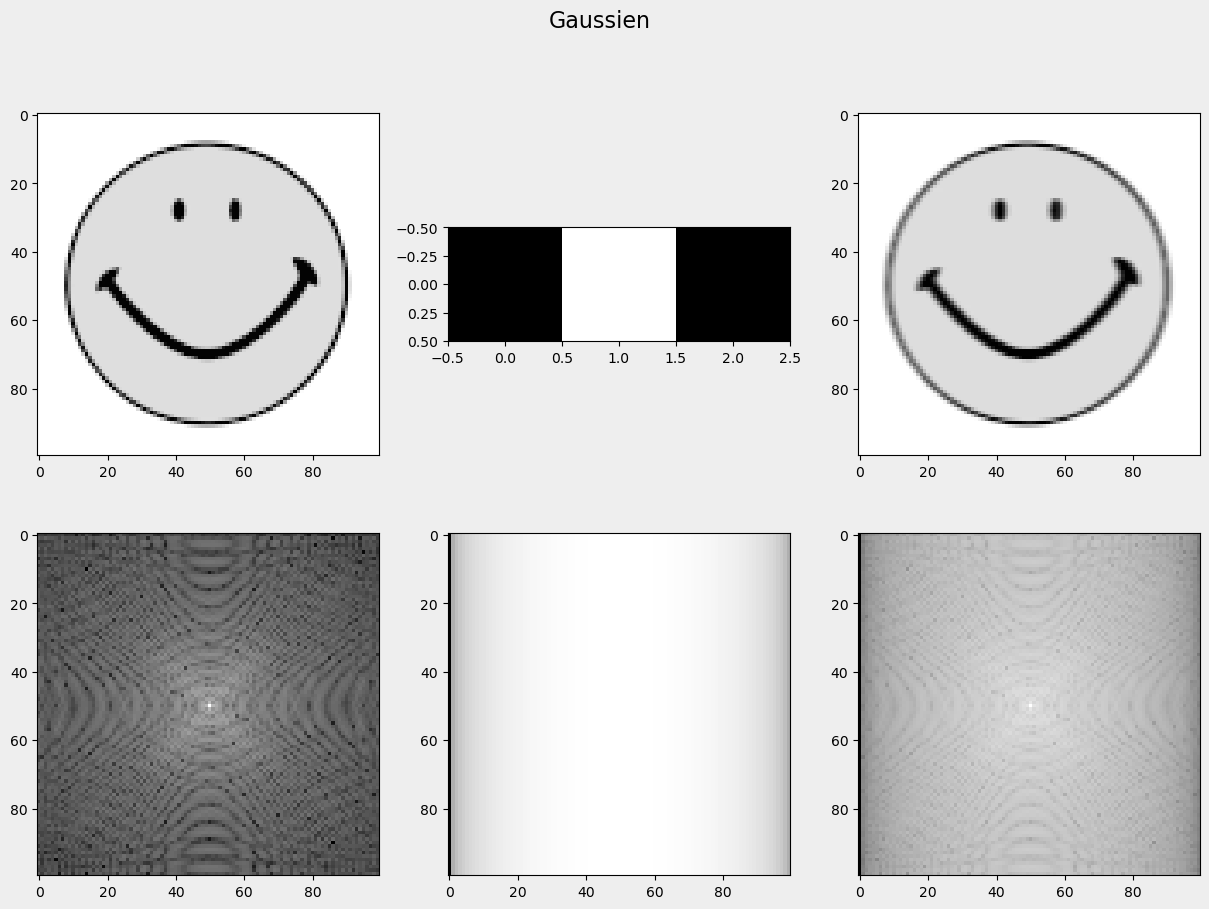

In [19]:
# Image originale
x = io.imread('../_static/smiley.png')
N = len(x)
x = ski.img_as_float(x)
X = np.fft.fftshift(np.fft.fft2(x))

# Gradient
def gradient(x):
    h = np.array([[1,-1]])
    H = np.fft.fftshift(np.fft.fft2(h, x.shape))
    y = ndi.convolve(x, h)
    Y = np.fft.fftshift(np.fft.fft2(y))
    return x, h, y, X, H, Y

# Gaussien (approximation)
def gaussian(x):
    h = np.array([[1,2,1]])
    H = np.fft.fftshift(np.fft.fft2(h, x.shape))
    y = ndi.convolve(x, h)
    Y = np.fft.fftshift(np.fft.fft2(y))
    return x, h, y, X, H, Y

# Mouvement
def motion(x):
    h = np.ones((20,1))
    H = np.fft.fftshift(np.fft.fft2(h, x.shape))
    y = ndi.convolve(x, h)
    Y = np.fft.fftshift(np.fft.fft2(y))
    return x, h, y, X, H, Y

# Filtre moyenneur
def mean(x):
    h = np.ones((10,10))
    H = np.fft.fftshift(np.fft.fft2(h, x.shape))
    y = ndi.convolve(x, h)
    Y = np.fft.fftshift(np.fft.fft2(y))
    return x, h, y, X, H, Y
        
# Passe-bas
def lowpass(x):
    fc = 15
    a = N//2-fc
    b = N//2+fc
    H = np.zeros(x.shape)
    H[a:b,a:b] = 1
    Y = X*H
    h = np.real(np.fft.ifft2(np.fft.ifftshift(H)))
    y = np.real(np.fft.ifft2(np.fft.ifftshift(Y)))
    return x, h, y, X, H, Y
        
# Passe-haut
def highpass(x):
    fc = 10
    a = N//2-fc
    b = N//2+fc
    H = np.ones(x.shape)
    H[a:b,a:b] = 0
    Y = X*H
    h = np.real(np.fft.ifft2(np.fft.ifftshift(H)))
    y = np.real(np.fft.ifft2(np.fft.ifftshift(Y)))
    return x, h, y, X, H, Y

def myshow(x, h, y, X, H, Y, title):
    # Affichage
    fig, axs = plt.subplots(2,3, figsize=(15,10), facecolor="#eee")
    axs[0,0].imshow(x, "gray")
    axs[0,1].imshow(h, "gray")
    axs[0,2].imshow(y, "gray")
    axs[1,0].imshow(np.log(1e-9+np.abs(X)), "gray")
    axs[1,1].imshow(np.log(1e-9+np.abs(H)), "gray")
    axs[1,2].imshow(np.log(1e-9+np.abs(Y)), "gray")
    plt.suptitle(title, fontsize=16)
    plt.show()
    print("\n\n\n")

x, h, y, X, H, Y = lowpass(x)
myshow(x, h, y, X, H, Y, "Filtre passe-bas")

x, h, y, X, H, Y = highpass(x)
myshow(x, h, y, X, H, Y, "Filtre passe-haut")

x, h, y, X, H, Y = mean(x)
myshow(x, h, y, X, H, Y, "Filtre moyenneur")

x, h, y, X, H, Y = gradient(x)
myshow(x, h, y, X, H, Y, "Gradient")

x, h, y, X, H, Y = gaussian(x)
myshow(x, h, y, X, H, Y, "Gaussien")

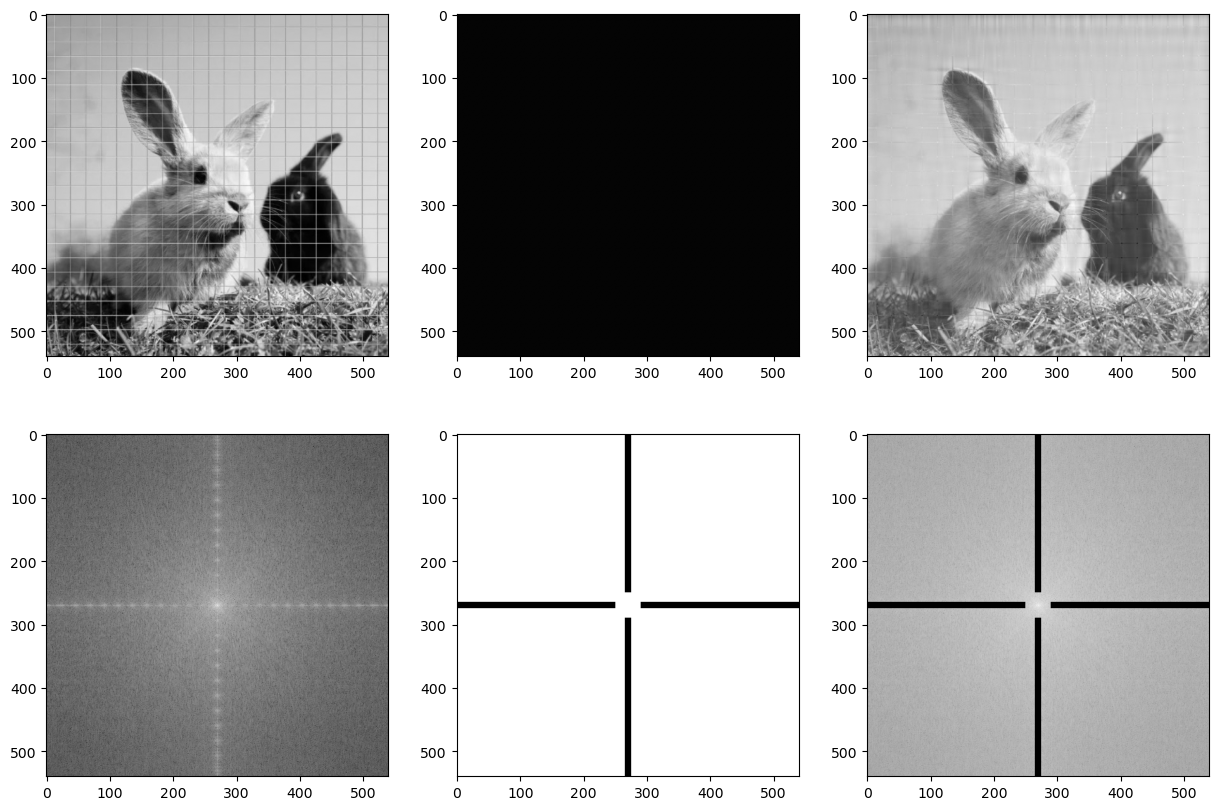

In [20]:
x = io.imread('lapin.jpg')
x = ski.img_as_float(x)
N = len(x)
X = np.fft.fftshift(np.fft.fft2(x))

H = np.ones(x.shape)
H[0:N, 265:275] = 0
H[265:275, 0:N] = 0
d = 20
H[N//2-d:N//2+d, N//2-d:N//2+d] = 1
Y = X*H

h = np.real(np.fft.ifft2(np.fft.ifftshift(H)))
y = np.real(np.fft.ifft2(np.fft.ifftshift(Y)))

fig, axs = plt.subplots(2,3, figsize=(15,10))
axs[0,0].imshow(x, "gray")
axs[0,1].imshow(h, "gray")
axs[0,2].imshow(y, "gray")
axs[1,0].imshow(np.log(1e-9+np.abs(X)), "gray")
axs[1,1].imshow(np.log(1e-9+np.abs(H)), "gray")
axs[1,2].imshow(np.log(1e-9+np.abs(Y)), "gray")
plt.show()